<a href="https://colab.research.google.com/github/Mayu8805/Mayuresh_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

In [4]:
import pandas as pd

df = pd.read_csv('/content/car_purchase_data.csv')
print(df.head())
print(df.shape)

    User ID  Gender  Age  Salary  Purchased
0  15624510    Male   19   19000          0
1  15810944    Male   35   20000          0
2  15668575  Female   26   43000          0
3  15603246  Female   27   57000          0
4  15804002    Male   19   76000          0
(400, 5)


## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('/content/car_purchase_data.csv')

print(df.head())
print(df.info())
print(df.isnull().sum())

    User ID  Gender  Age  Salary  Purchased
0  15624510    Male   19   19000          0
1  15810944    Male   35   20000          0
2  15668575  Female   26   43000          0
3  15603246  Female   27   57000          0
4  15804002    Male   19   76000          0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   User ID    400 non-null    int64 
 1   Gender     400 non-null    object
 2   Age        400 non-null    int64 
 3   Salary     400 non-null    int64 
 4   Purchased  400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB
None
User ID      0
Gender       0
Age          0
Salary       0
Purchased    0
dtype: int64


### Step 2: Split features and target

In [6]:
# Select the input features
X = df[['Age', 'Salary']]

# Select the target variable
y = df['Purchased']

# Display the features and target
print("Features (X):")
print(X.head())

print("\nTarget (y):")
print(y.head())

Features (X):
   Age  Salary
0   19   19000
1   35   20000
2   26   43000
3   27   57000
4   19   76000

Target (y):
0    0
1    0
2    0
3    0
4    0
Name: Purchased, dtype: int64


### Step 3: Train/Test Split

In [15]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=10)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

Training data shape: (300, 2)
Testing data shape: (100, 2)
Training target shape: (300,)
Testing target shape: (100,)


### Step 4: Feature Scaling

In [16]:
from sklearn.preprocessing import StandardScaler

# Create the scaler
sc = StandardScaler()

# Fit on training data and transform it
X_train = sc.fit_transform(X_train)

# Transform testing data using the same scaler
X_test = sc.transform(X_test)

print("Scaled training data (first 5 rows):")
print(X_train[:5])

print("\nScaled testing data (first 5 rows):")
print(X_test[:5])

Scaled training data (first 5 rows):
[[-0.93894518  0.26049952]
 [-0.93894518  0.43327002]
 [ 0.3177076   0.05893394]
 [ 2.15435398 -1.03527922]
 [ 0.8010356   0.34688477]]

Scaled testing data (first 5 rows):
[[ 0.4143732  -0.14263164]
 [-0.06895479  0.03013885]
 [ 0.4143732   0.57724543]
 [ 0.89770119 -0.66094314]
 [-1.42227318 -0.63214806]]


### Step 5: Train Logistic Regression Model

In [17]:
from sklearn.linear_model import LogisticRegression

# Create the logistic regression model
model = LogisticRegression()

# Train the model using the training data
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


### Step 6: Predict and Evaluate

In [18]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Predict purchases using the test data
y_pred = model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy percentage:", accuracy * 100, "%")

# Display the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Display the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy: 0.9
Accuracy percentage: 90.0 %

Confusion Matrix:
[[64  5]
 [ 5 26]]

Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.93      0.93        69
           1       0.84      0.84      0.84        31

    accuracy                           0.90       100
   macro avg       0.88      0.88      0.88       100
weighted avg       0.90      0.90      0.90       100



### Step 7: Visualization of Decision Regions

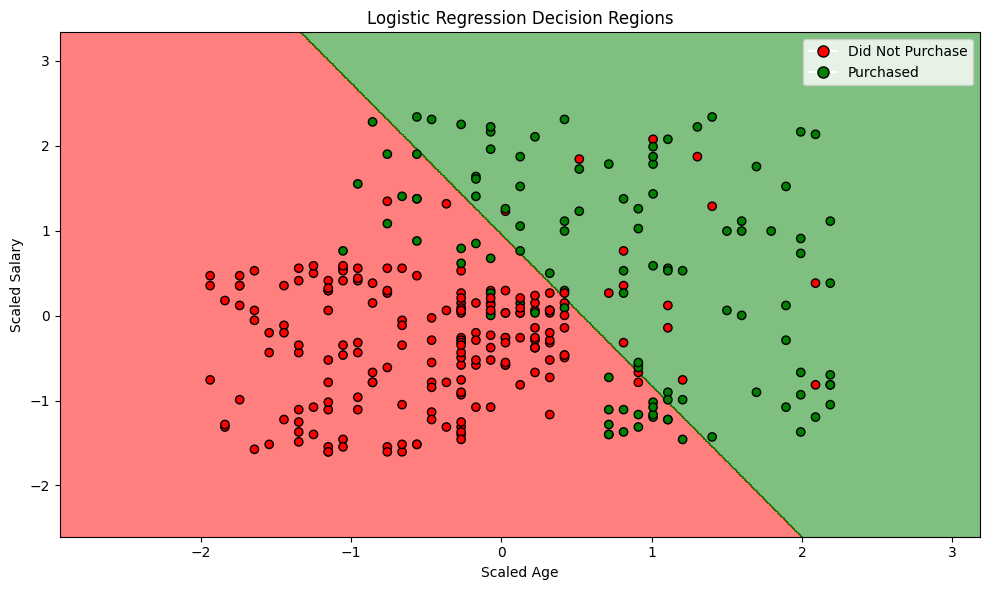

In [13]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D

# Use the scaled training data
X_set, y_set = X_train, y_train

# Create a grid of points
X1, X2 = np.meshgrid(
    np.arange(X_set[:, 0].min() - 1,
              X_set[:, 0].max() + 1, 0.01),
    np.arange(X_set[:, 1].min() - 1,
              X_set[:, 1].max() + 1, 0.01)
)

# Plot the decision regions
plt.figure(figsize=(10, 6))

Z = model.predict(
    np.array([X1.ravel(), X2.ravel()]).T
).reshape(X1.shape)

plt.contourf(
    X1, X2, Z,
    alpha=0.5,
    cmap=ListedColormap(('red', 'green'))
)

# Plot the training data points
plt.scatter(
    X_set[:, 0],
    X_set[:, 1],
    c=y_set,
    cmap=ListedColormap(('red', 'green')),
    edgecolors='black'
)

# Add title and axis labels
plt.title('Logistic Regression Decision Regions')
plt.xlabel('Scaled Age')
plt.ylabel('Scaled Salary')

# Add a legend
legend_items = [
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='red',
        markeredgecolor='black',
        label='Did Not Purchase',
        markersize=8
    ),
    Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor='green',
        markeredgecolor='black',
        label='Purchased',
        markersize=8
    )
]

plt.legend(handles=legend_items)
plt.tight_layout()
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

### 1. Logistic regression outputs probabilities — why can it still be used for classification?

Logistic regression predicts the probability that a customer belongs to a class. Using a threshold of 0.5, the model classifies a customer as purchasing a car if the probability is at least 0.5; otherwise, it predicts that the customer will not purchase a car.

### 2. Based on your model, which customers are more likely to purchase a car?

Customers' age and salary influence the model's predictions. In general, older customers and customers with higher salaries may be more likely to purchase a car in this dataset. However, the model's predictions depend on the combination of both features.

### 3. What factors might cause low accuracy in this task?

Low accuracy may result from a small dataset, overlapping characteristics between customers who purchase and those who do not, missing important features, noisy data, or an unsuitable model. The train-test split can also affect the measured accuracy.

### 4. Propose additional features or preprocessing steps that could improve accuracy.

Additional features such as credit score, employment status, existing debt, and monthly expenses could improve predictions. We could also test different train-test splits, use cross-validation, tune model parameters, and compare logistic regression with other classification algorithms.